
<br>

### Common SciPy hypothesis tests

| Statistical test    | SciPy function         |
| ------------------- | ---------------------- |
| One-sample t-test   | `stats.ttest_1samp()`  |
| Independent t-test(2sample)  | `stats.ttest_ind()`    |
| Paired t-test       | `stats.ttest_rel()`    |
| Binomial test       | `stats.binomtest()`    |
| Chi-square test     | `stats.chisquare()`    |
| Pearson correlation | `stats.pearsonr()`     |
| Mann-Whitney U      | `stats.mannwhitneyu()` |

P-value interpretation:

- `p < 0.05`: Reject the null hypothesis (at 5% significance level).
- `p >= 0.05`: Fail to reject the null hypothesis.

<br>


<br>

## A-B Testing case study: 

<br>

**Product:** e-commerce website। "Buy" button red (A, control) থেকে blue (B, treatment) করা হলো।

| জিনিস | মান |
|---|---|
| Unit | user, random 50/50 ভাগ, একজন user সবসময় একই version দেখে |
| Primary metric | click rate (Buy click ÷ visitor), baseline = 10% |
| Guardrail metric | refund rate, revenue per user |
| α | 0.05 |
| Power | 80% |
| Business threshold (MDE) | কমপক্ষে **+0.5 percentage point (pp)**। এর কম হলে design, dev আর maintenance খরচ উঠে না |
| Planned sample | প্রতি group-এ ≈ 56,500, তাই 60,000 নিলাম |

**আগে থেকে ঠিক করা decision rule: blue ship করব যদি**
1. p < 0.05
2. CI পুরোটা +0.5 pp-এর উপরে
3. Guardrail ঠিক থাকে
4. Plan মেনে চলা হয় (peek না, একটাই primary metric)

## 7টা case

**Case 1: বিশাল n, p ছোট (plan ছাড়া)**
- প্রতি group-এ 20 লক্ষ user। A = 10.00%, B = 10.10%।
- p ≈ 0.001, difference = 0.1 pp, CI = **+0.04 থেকে +0.16 pp**।

**Case 2: ছোট n, p বড় (plan ছাড়া)**
- প্রতি group-এ 200 user। A = 10%, B = 14%।
- p ≈ 0.22, CI = **−2.4 থেকে +10.4 pp**।

**Case 3: 20টা metric দেখলাম**
- n = 60,000/group। Primary metric (click): p = 0.45।
- বাকি 19টা metric-এর একটায় p = 0.03।

**Case 4: রোজ peek করলাম**
- 14 দিনের plan। দিন 6-এ p = 0.04, তাই থামিয়ে দিলাম।
- Plan মতো 14 দিন চালালে p হতো ≈ 0.31 (ধরে নিচ্ছি)।

**Case 5: click বাড়ল, কিন্তু business খারাপ**
- n = 60,000/group। A = 10.0%, B = 10.8%।
- p < 0.001, CI = +0.45 থেকে +1.15 pp।
- কিন্তু refund rate 2.0% → 2.6%, আর revenue per user 3% কমেছে।

**Case 6: ঠিকমতো plan, effect নেই**
- n = 60,000/group। A = 10.00%, B = 10.05%।
- p ≈ 0.77, CI = **−0.29 থেকে +0.40 pp**।

**Case 7: ঠিকমতো plan, সত্যিই ভালো**
- n = 60,000/group। A = 10.0%, B = 11.0%।
- p < 0.0001, CI = **+0.65 থেকে +1.35 pp**। Guardrail ঠিক, peek নেই, একটাই primary metric।

## Summary table

| Case | p-value | শুধু p দিয়ে সিদ্ধান্ত | p যা বলে না | আসল সিদ্ধান্ত | p একা ঠিক ছিল? |
|---|---|---|---|---|---|
| 1 | 0.001 | Ship করো | Effect মাত্র 0.04 থেকে 0.16 pp, threshold 0.5-এর অনেক নিচে | **Ship করো না** | ❌ |
| 2 | 0.22 | "Blue কাজ করে না" | Test দুর্বল, CI −2.4 থেকে +10.4, কিছুই বলা যায় না | **Inconclusive**, plan করে আবার চালাও | ❌ |
| 3 | 0.03 (1টা metric) | Ship করো | 20টা দেখলে luck-এ একটা আসার সম্ভাবনা ≈ 64%, primary metric-এ কিছু নেই | **Ship করো না**, নতুন test-এ যাচাই করো | ❌ |
| 4 | 0.04 (দিন 6) | Ship করো | Peek করে থামানো মানে বহু লটারির একটা জেতা | **Result অগ্রহণযোগ্য**, plan মতো শেষ করো | ❌ |
| 5 | <0.001 | Ship করো | Refund বেড়েছে, revenue কমেছে | **Ship করো না**, কারণ খোঁজো | ❌ |
| 6 | 0.77 | "Difference নেই" | CI-র উপরের সীমা +0.40 < 0.5, তাই লাভজনক effect থাকার সম্ভাবনা নেই | **Ship করো না**, red-ই থাকুক | ⚠️ ফল ঠিক, কিন্তু প্রমাণ CI থেকে আসে |
| 7 | <0.0001 | Ship করো | CI +0.65 থেকে +1.35, threshold-এর উপরে, guardrail ঠিক | **Ship করো** | ✅ (বাকি শর্ত মিলেছিল বলেই) |

7টার মধ্যে p একা পুরোপুরি ঠিক সিদ্ধান্ত দিয়েছে মাত্র Case 7-এ, আর সেখানেও বাকি শর্ত মিলেছিল বলে।

## কেন p-value দিয়ে হচ্ছে না: দুটো জোড়া দেখো

**Case 1 vs Case 7:** দুটোতেই p খুব ছোট, কিন্তু সিদ্ধান্ত উল্টো। পার্থক্য p-তে নেই, আছে effect size আর CI-তে।

**Case 2 vs Case 6:** দুটোতেই p > 0.05, কিন্তু অর্থ উল্টো।
- Case 2-এর CI বিশাল চওড়া, তাই test কিছু বলতে পারছে না।
- Case 6-এর CI সরু আর threshold-এর নিচে, তাই "লাভজনক effect নেই" বলা যায়।

## Case 1-এ সমস্যা কী ছিল?

1. **n বিশাল হলে ছোট effectও significant হয়।** Standard error ∝ 1/√n, তাই n বাড়লে SE ছোট হয় আর 0.1 pp-ও "অদ্ভুত" দেখায়। p ছোট মানে "effect আছে", "effect বড়" না।
2. **p শুধু একটা প্রশ্নের উত্তর দেয়:** "A, B একই হলে এই data কতটা অদ্ভুত?" "কতটুকু পার্থক্য?" এর উত্তর দেয় CI: +0.04 থেকে +0.16 pp।
3. **CI পুরোটা threshold-এর নিচে।** Best case-এও 0.16 < 0.5। Button বদলাতে খরচ হয়েছে, কিন্তু লাভ খরচ তুলতে পারবে না।
4. **Plan ছিল না।** 20 লক্ষ user ব্যবহার করা হলো এমন পার্থক্য ধরতে, যেটা business-এর কাজেই লাগে না। আগে MDE ঠিক করলে বুঝতে পারতে 60,000-ই যথেষ্ট।

## সিদ্ধান্ত নেওয়ার ক্রম

1. আগে MDE আর sample size ঠিক করো (Case 2, 1-এর সমস্যা)।
2. একটা primary metric রাখো (Case 3)।
3. Peek না করে plan শেষ করো (Case 4)।
4. p দেখো, তারপর effect size + CI-কে threshold-এর সঙ্গে মেলাও (Case 1, 6, 7)।
5. Guardrail দেখো (Case 5)।
6. তারপর ship বা না।

## Note-এ যোগ করার লাইন

> p-value বলে "luck-এ এমন data আসা কতটা অসম্ভব"। কিন্তু (1) Case 1 vs 7-এ p সমান ছোট হলেও CI আলাদা বলে সিদ্ধান্ত উল্টো, (2) Case 2 vs 6-এ p সমান বড় হলেও CI-র চওড়ায় অর্থ উল্টো, (3) অনেক metric দেখা বা peek করা p-কে মিথ্যা করে দেয়, (4) business guardrail p-তে নেই। তাই সিদ্ধান্ত নিই p + effect size/CI + power + plan + guardrail মিলিয়ে।

(Case 5-এর refund আর revenue-র সংখ্যা, আর Case 4-এর "14 দিনে p = 0.31" আমার বানানো উদাহরণ। বাকি p আর CI standard two-proportion z-test দিয়ে হিসাব করা।)

চাইলে Case 1, 2, 6, 7 Python simulation-এ বানিয়ে দিতে পারি, যেখানে CI আর threshold একই plot-এ দেখা যাবে।

<br>

# `# Day01: CLT, CI and p-value`

<br>

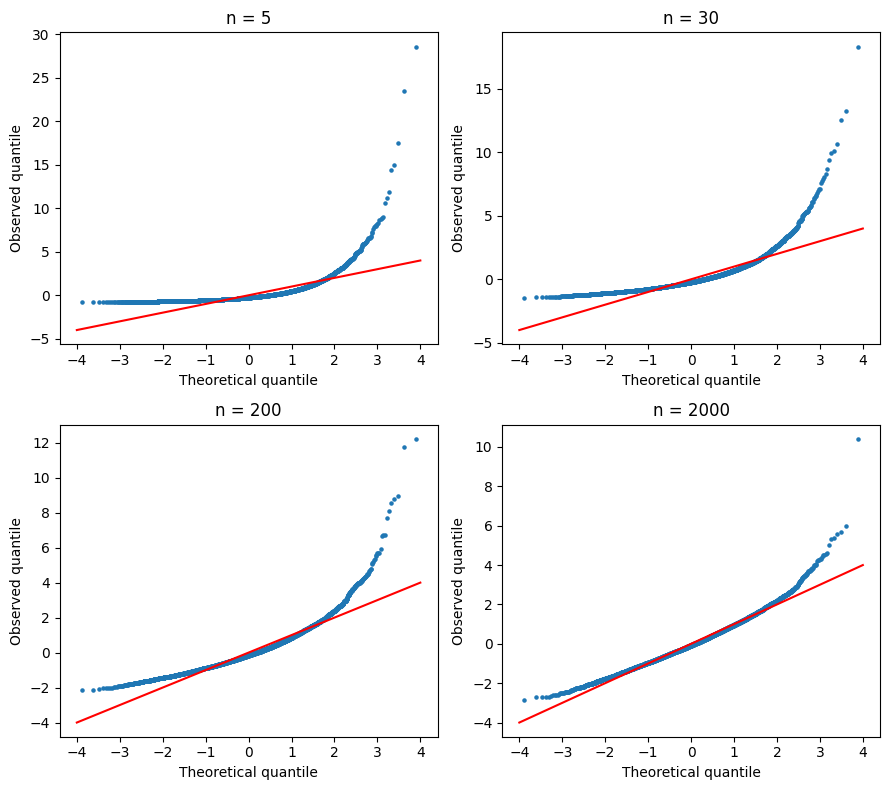

In [17]:
import numpy as np 
import scipy.stats as stats 
import matplotlib.pyplot as plt 

fig, axes = plt.subplots(2,2,figsize=(9,8))
for ax,size in zip(axes.ravel(),[5,30,200,2000]):
    
    # standradize observered quantiles(y-axis)
    means = np.mean(np.random.lognormal(mean=0,sigma=1.5,size=(10000,size)),axis=1)
    z = (means - means.mean())/means.std()
    z = np.sort(z)
    
    # theoritical quantile (divide data into equal parts) -> (x-axis)
    m = len(z)
    prob = (np.arange(1,m+1) - 0.5)/m  # 1-1 =0 (to skip that - 0.5)
    theoritical_quantile = stats.norm.ppf(prob)
    ax.scatter(theoritical_quantile,z,s=5)
    
    # reference line:
    ax.plot([-4,4],[-4,4],color='red')
    
    ax.set_xlabel("Theoretical quantile")
    ax.set_ylabel("Observed quantile")
    ax.set_title(f"n = {size}")
plt.tight_layout()

#
#
# Learning:
# i) Right Skewed.
# ii) n increased then it's become normal. (CTL)
# iii) Lognormal(1.5) -> the tail is too long. That's why we need big n.
#
#

In [ ]:

# If we have given population portion then, we use wald or wilson CI

# rvs-> random variates:
n,p,trails = 500,0.1,10_000
hits = 0 

for _ in range(trails):
    sample = stats.bernoulli.rvs(p=p,size=n)
    p_hat = np.mean(sample)
    se = np.sqrt( p_hat *(1-p_hat)*(1/n))
    lower,upper = p_hat - 1.96*se, p_hat + 1.96*se
    if lower<= p <= upper:
        hits +=1
print(f"Wald Coverage: p = {p}, n={n} => ",hits/trails)
    
    
# ===== Wilson Conversion: =======
n,p,trails = 500,0.1,10_000
hits = 0 

for _ in range(trails):
    sample = stats.bernoulli.rvs(p=p,size=n)
    p_hat = np.mean(sample)
    # see the formula from note
    z = 1.96 # for CI = 95%
    denom = 1 + (z**2/n)
    left_side = p_hat + (z**2 / (2*n))
    right_side = z * np.sqrt(
        (p_hat * (1-p_hat) / n) +
        (z**2 / (4*n**2))
    )
    lower = (left_side-right_side)/denom
    upper = (left_side+right_side)/denom
    if lower<= p <= upper:
        hits +=1
print(f"Wilson Coverage: p = {p}, n={n} => ",hits/trails)
    


# wild interval:
# rvs-> random variates:
n,p,trails = 100,0.01,10_000
hits = 0 

for _ in range(trails):
    sample = stats.bernoulli.rvs(p=p,size=n)
    p_hat = np.mean(sample)
    se = np.sqrt( p_hat *(1-p_hat)*(1/n))
    lower,upper = p_hat - 1.96*se, p_hat + 1.96*se
    if lower<= p <= upper:
        hits +=1
print(f"Wald Coverage: p = {p}, n={n} => ",hits/trails)
    
    
# ===== Wilson Conversion: =======
hits = 0 

for _ in range(trails):
    sample = stats.bernoulli.rvs(p=p,size=n)
    p_hat = np.mean(sample)
    # see the formula from note
    z = 1.96 # for CI = 95%
    denom = 1 + (z**2/n)
    left_side = p_hat + (z**2 / (2*n))
    right_side = z * np.sqrt(
        (p_hat * (1-p_hat) / n) +
        (z**2 / (4*n**2))
    )
    lower = (left_side-right_side)/denom
    upper = (left_side+right_side)/denom
    if lower<= p <= upper:
        hits +=1
print(f"Wilson Coverage: p = {p}, n={n} => ",hits/trails)
    

# 
#
# If p near to zero and n is small, the wald say convergae will be 95% but we get only 64%
# 
#



Wald Coverage: p = 0.1, n=500 =>  0.9474
Wald Coverage: p = 0.1, n=500 =>  0.9568
Wald Coverage: p = 0.01, n=100 =>  0.6417
Wald Coverage: p = 0.01, n=100 =>  0.9241


<br>

---

`**1.** A আর B দুটোই একই distribution থেকে আসছে (H0 সত্য)। ১০,০০০ বার t-test চালিয়ে p-value-এর histogram আঁকো। এটা কি Uniform? কত শতাংশ p < 0.05?`

<br>

### Figure 1: H0 is true (A and B are the same) - histogram of p-values

**What I did:** Drew both A and B from Normal(0, 1), n = 100, and ran a Welch t-test 10,000 times.

**What I saw:** 10,000 p-values / 20 bins ≈ 500 per bin, so the histogram is flat (uniform). p < 0.05 = [ ]%, about 5%.

**Why:** Under H0, p-values are uniform on [0, 1], so P(p < α) = α. With α = 0.05 this is 5%; with α = 0.01 it would be 1%. It depends on α, not on n.

**False positive:** We built A and B to be identical, so the truth is "no difference". Yet about 500 tests said "different" (p < 0.05). Those answers are wrong:
- "Positive" = the test says there is a difference.
- "False" = that claim is wrong.

Same as a false positive in an ML confusion matrix. Example: run #347 gave p = 0.02 purely by luck.

**Alarm analogy:**
- Figure 1: NO fire (no difference), but the alarm still rings 5 times out of 100 → false alarm rate = α.
- Figure 2: a real fire (real difference), and the alarm rings almost every time → power.
- Figure 3: a real fire, but fewer sensors (small n), so the alarm often stays silent → low power, Type II error.


<br>

p < 0.05 =  0.0494


Text(0, 0.5, 'count')

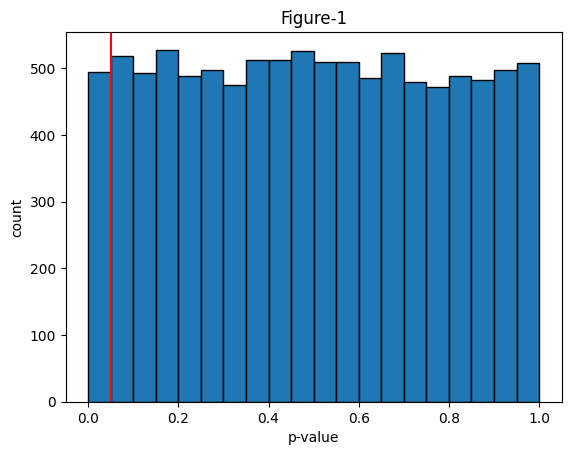

In [55]:


trails = 10_000
A = np.random.lognormal(mean=0,sigma=1.5,size=(trails,10000))
B = np.random.lognormal(mean=0,sigma=1.5,size=(trails,10000))

# two sample test:(welch t-test -> equal_var=False)
# for A/B testing welch t-test give good results
result = stats.ttest_ind(A,B,equal_var=False,axis=1)
p = result.pvalue
print("p < 0.05 = ", np.mean((p<0.05)))

# draw a histrogram:
plt.hist(p,bins=20,edgecolor='k')

# Type-One Error:
# it's about 0.05, cause there will be a pobability of getting wrong: 5% 
# false positive(left side all false positive, cause there is no difference between a,b, Ho is true)
plt.axvline(0.05,color='red')
plt.title("Figure-1")
plt.xlabel("p-value")
plt.ylabel("count")



p < 0.05 =  0.9993


Text(0, 0.5, 'count')

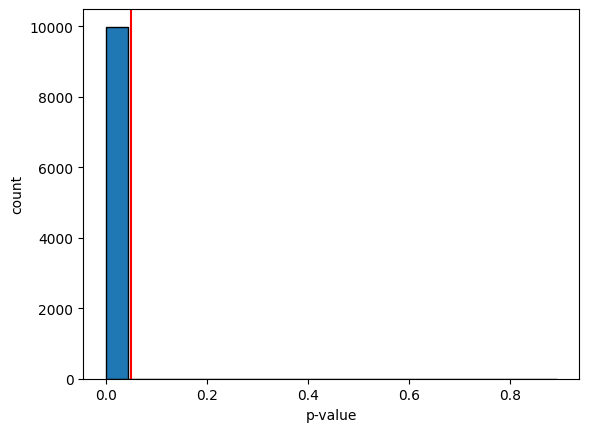

In [49]:

# == Let's do some changes on B: ===

trails = 10_000
A = np.random.lognormal(mean=0,sigma=1.5,size=(trails,10000))
B = np.random.lognormal(mean=0.3,sigma=1.5,size=(trails,10000))

# two sample test:(welch t-test -> equal_var=False)
# for A/B testing welch t-test give good results
result = stats.ttest_ind(A,B,equal_var=False,axis=1)
p = result.pvalue
print("p < 0.05 = ", np.mean((p<0.05)))

# draw a histrogram:
plt.hist(p,bins=20,edgecolor='k')

# Type-One Error:
# it's about 0.05, cause there will be a pobability of getting wrong: 5% 
# false positive(left side all false positive, cause there is no difference between a,b, Ho is true)
plt.axvline(0.05,color='red')
plt.xlabel("p-value")
plt.ylabel("count")

p < 0.05 =  0.1334


Text(0, 0.5, 'count')

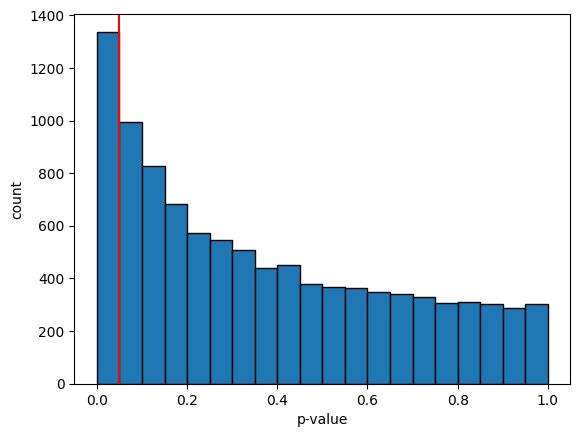

In [50]:

# == Let's do some changes on B: ===

trails = 10_000
A = np.random.lognormal(mean=0,sigma=1.5,size=(trails,100))
B = np.random.lognormal(mean=0.3,sigma=1.5,size=(trails,100))

# two sample test:(welch t-test -> equal_var=False)
# for A/B testing welch t-test give good results
result = stats.ttest_ind(A,B,equal_var=False,axis=1)
p = result.pvalue
print("p < 0.05 = ", np.mean((p<0.05)))

# draw a histrogram:
plt.hist(p,bins=20,edgecolor='k')

# Type-One Error:
# it's about 0.05, cause there will be a pobability of getting wrong: 5% 
# false positive(left side all false positive, cause there is no difference between a,b, Ho is true)
plt.axvline(0.05,color='red')
plt.xlabel("p-value")
plt.ylabel("count")

In [5]:

import scipy.stats as stats
import numpy as np 

# revenew of a company:
# why -> Trials? Cause, In question they said conversion. 
# That's mean we need mulptiple trials. 
sigma, trails = 2.0, 10_000
mean = 0 

# mean of lognormal distribution:(pdf)
true_mean = np.exp(mean + sigma**2/2)

for n in [100,5000]:
    # need to find conversation rate:
    hits = 0 
    # A/B testing noramlly -> two-tailed test -> 95%+2.5% = 97.5 -> degree_of_freedom
    critical_value = stats.t.ppf(0.975,n-1)
    
    # ======= see the a/b testing note how to measue CI with ppf =======
    
    for _ in range(trails):
        # CI = point estimate ± (critical value × SE)
        sample = np.random.lognormal(mean,sigma,size=n)
        point_estimate = sample.mean()
        se = sample.std(ddof=1)/np.sqrt(n)
        margin = critical_value * se 
        
        lower = point_estimate - margin
        upper = point_estimate + margin 
        
        if lower <= true_mean <= upper:
            hits +=1 
    print(f"n= {n} : coverage = {hits/trails:.3f}")
        



n= 100 : coverage = 0.740
n= 5000 : coverage = 0.901


<br>
<br>

# `#02: Day 02: Two-proportion z-test, Welch t-test, Mann-Whitney `

<br>
<br>

In [ ]:

# day2: problem1 

def two_prop_ztest(x1,n1,x2,n2):
    """
    two proption -> two tailed test
    return CI,  
    """
    p1 = x1/n1 
    p2 = x2/n2 
    
    # two proportion z-test (Pooled SE)
    p_pool = (x1+x2)/(n1+n2)
    SE_POOLED = np.sqrt(p_pool * (1-p_pool) * (1/n1 + 1/n2))
    z = (p2-p1)/SE_POOLED 
    
    # p -value: (two-trailed test)
    p =  2 * (1 - stats.norm.cdf(abs(z)))
    

    # lift: 1. Absolute lift: CI 
    abs_lift = p2-p1
    UNPOOLED_SE = np.sqrt((p1*(1-p1)/n1) + (p2*(1-p2)/n2) )
    # quesetion say z test
    critical_value = stats.norm.ppf(0.975)
    abs_CI_upper, abs_CI_lower = abs_lift + critical_value*UNPOOLED_SE, abs_lift - critical_value*UNPOOLED_SE
    abs_CI = (abs_CI_upper.item(),abs_CI_lower.item())
    
    # lift: 2. Relative Lift: CI 
    rel_lift = p2-p1/p1 
    log_ratio = np.log(p2/p1)
    se_log = np.sqrt( ((1-p1)/(n1*p1))  + ((1-p2)/(n2*p2)) )
    rel_CI = (np.exp(log_ratio - critical_value*se_log).item() - 1,
          np.exp(log_ratio + critical_value*se_log).item() - 1)
    
    return z.item(),p.item(), abs_lift, abs_CI, rel_lift, rel_CI


n1 = n2 = 200_000
x1, x2 = 0.100 * n1, 0.103 * n2 
two_prop_ztest(x1,n1,x2,n2)



(3.141443063780299,
 0.0016811749283662802,
 0.002999999999999989,
 (0.004871693772716592, 0.0011283062272833856),
 -0.897,
 (0.011178012789151426, 0.04917233818573541))

In [32]:

# with scipy library: 
from statsmodels.stats.proportion import proportions_ztest
z_sm, p_sm = proportions_ztest([x2, x1], [n2, n1])
print(z_sm, p_sm)

3.141443063780299 0.0016811749283661913


In [ ]:

#
# day2: problem2 
# delta method(log) -> (relative lift in day02: qustion - 1)
# bootstrap -> (day02: question - 3)
#

# here, relative lift is related to conversation data: we can create with bernoulli distribution. But will use manually here,
n = 200_000 # total user in each group 
x1, x2 = 20_000, 20_600 # no. converted user

control   = np.concatenate((np.ones(x1), np.zeros(n - x1)))
treatment = np.concatenate((np.ones(x2), np.zeros(n - x2)))
critical_value = stats.norm.ppf(0.975)   # 95% two-tailed -> 1.96

p1 = control.mean()
p2 = treatment.mean()


# CI: relative lift:
rel_lift = (p2-p1)/p1 
log_ratio = np.log(p2/p1)
se_log = np.sqrt((1-p1)/(n*p1) + (1-p2)/(n*p2))
rel_CI = (np.exp(log_ratio - critical_value*se_log).item() - 1,
          np.exp(log_ratio + critical_value*se_log).item() - 1)

B = 2000
diffs = []
for _ in range(B):
    c = np.random.choice(a=control,size=len(control),replace=True)
    t = np.random.choice(a=treatment,size=len(treatment),replace=True)
    
    # here, also we need relative:
    p1_star, p2_star = c.mean(), t.mean()
    diffs.append((p2_star - p1_star) / p1_star)
    
# as two tailed test: 2.5, 95+2.5
lower,upper = np.percentile(diffs, [2.5,97.5])


""" 
“For relative lift, I build the CI on the log scale, because a ratio’s distribution is skewed.
ln(p2/p1) is close to normal, so I use ±1.96 × SE there, then convert back with exp. With large samples, 
this delta-method CI and a bootstrap CI give almost the same result. In my check, both were about [1.1%, 4.9%] for 10.0% vs 10.3% 
with 200k users per group.”

# when use boostrap:
“When the sample is small, the rate is very low, or the metric has no simple SE formula, like a median, 
a p95 latency or a ratio of two metrics. Bootstrap needs no formula and naturally captures skew. 
The cost is more computation.”

# decision quesiton: 2 
“Both, clearly labeled: +0.3pp absolute, which is +3% relative. Absolute lift converts directly to money; 
relative lift lets me compare tests with different baselines.”

# decison question: 1 
“For conversion I use a two-proportion z-test with pooled SE for the p-value and unpooled SE for the CI. 
For revenue I use Welch’s t-test with a bootstrap CI, not Mann–Whitney, because the business cares about the mean.”

"""

print("Relative lift CI: ",rel_CI)
print("Boostrap CI: ", lower, upper)


Relative lift CI:  (0.011178012789151426, 0.04917233818573541)
Boostrap CI:  0.012063615353380467 0.04881136083854308


In [36]:
a = np.array([1,2,3])
b = np.array([2,3,4])
np.concat((a,b),axis=0)

array([1, 2, 3, 2, 3, 4])

In [78]:

import numpy as np 
import scipy.stats as stats

# day2: problem3
n = 10_0000
n95 = int(n*0.95)
control = np.concat( (np.random.lognormal(size=(n-n95)),np.zeros(shape=n95)), axis=0)

# 10% increase: 110% = 1.1
buyer_t = np.random.lognormal(size=(n-n95)) * 1.10
treatment = np.concat((buyer_t,np.zeros(n95)),axis=0)

# welch t-test
wel_t_val, wel_pvalue = stats.ttest_ind(a=control,b=treatment, equal_var=False)

# mann-whitney:(see note to clarify U value)
U, man_pvalue = stats.mannwhitneyu(x=control,y=treatment)


# Bootstrap CI - We don’t have the population, only a sample. 
# So we treat the sample as a mini-population,
# resample from it many times, and use the spread of the results to get the CI.”

B = 2_000
diffs = []
for _ in range(B):
    c = np.random.choice(control,size=len(control),replace=True)
    t = np.random.choice(treatment,size=len(treatment),replace=True)
    diffs.append(t.mean()-c.mean())
lower, upper = np.percentile(diffs, [2.5, 97.5])


# Welch p < 0.05: evidence of a difference in mean revenue per user
print("Welch p:", wel_pvalue)

# Mann-Whitney: does a random B user tend to rank higher than a random A user?
# p < 0.05 -> yes (rank shift); p high -> no evidence of a rank shift
# p < 0.05 not but why? cause almost all values are zero.
print("Mann-Whitney p:", man_pvalue)

# CI[] -> zero isn't preesnt, it's also say there is a difference like welch
print("Bootstrap 95% CI for mean diff:", lower, upper)




#
# “Welch and bootstrap say mean revenue is up. Mann–Whitney says a typical user is not better off, because 95% of 
# users spend 0 in both groups. No contradiction: different questions.”
#
#




Welch p: 0.1080864937794658
Mann-Whitney p: 0.9249704820517395
Bootstrap 95% CI for mean diff: -0.0009007438513091652 0.010570667098011667


<br>
<br>

# `#03: Day 3 — Power, sample size and MDE`

<br>
<br>

In [ ]:

import scipy.stats as stat
from statsmodels.stats.power import NormalIndPower

def per_group_size(p0,mde_abs,alpha=0.05,power=0.8):
    """
    p1 = p0(baseline).
    mde_as: Minimum Detectable Effect.
    """
    p1 = p0 
    p2 = p1 + mde_abs 
    
    # two tailed test, 1 - alpha/2
    Z_alphaby2 = stats.norm.ppf( 1 - alpha/2 )
    Z_B = stat.norm.ppf(power) 
    n = (Z_alphaby2 + Z_B)**2 * (p1*(1-p1) + p2*(1-p2)) / mde_abs**2 
    return n 
     
print(per_group_size(p0=0.2,mde_abs=0.01))
print(per_group_size(p0=0.10,mde_abs=0.00125))

print()
print("======with library======")
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

# p2,p1 -> give input:
h = proportion_effectsize(0.2+0.01, 0.2)         
NormalIndPower().solve_power(effect_size=h, alpha=0.05, power=0.8,
                             ratio=1, alternative="two-sided")


25579.499054243686
909206.379547264

======with library======


25579.95659617889